# 02 - Baseline Models

**Goal:** set a reference score for fraud detection that later models must beat.

- Data: credit card transactions after removing duplicates (283,726 rows, 473 fraud = 0.167%).
- Split: stratified 80/20, so the test set keeps the same fraud rate (95 frauds in test).
- Model: Logistic Regression with class_weight='balanced'. StandardScaler is applied to Time and Amount inside a Pipeline.
- Metrics: PR-AUC (main), precision, recall, F1, and the confusion matrix. Accuracy is not used because the data is highly imbalanced.

In [1]:
import numpy as np 
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv('../data/raw/creditcard.csv')
df

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [3]:
df.shape

(284807, 31)

In [4]:
df.drop_duplicates(inplace=True)

In [5]:
df.shape

(283726, 31)

Removed 1,081 duplicate rows: 284,807 to 283,726.

In [6]:
X=df.drop(columns='Class')
y=df['Class']

In [7]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [8]:
scaling_cols=['Amount','Time']

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

preprocessor=ColumnTransformer([
    ('scaling',StandardScaler(),scaling_cols)
],remainder='passthrough')

base_pipe=Pipeline([
    ('preprocess',preprocessor),
    ('model',LogisticRegression(class_weight='balanced'))
])

base_pipe.fit(X_train,y_train)
y_pred=base_pipe.predict(X_test)


Accuracy Score:- 0.9752405455891164
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746



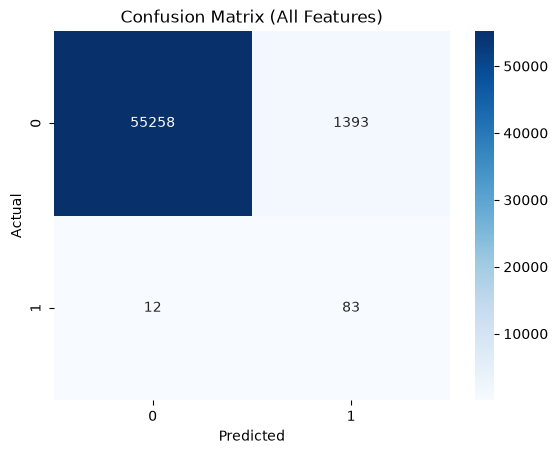

In [10]:
from sklearn.metrics import classification_report ,accuracy_score, confusion_matrix
print(f'Accuracy Score:- {accuracy_score(y_test,y_pred)}')
print(classification_report(y_test,y_pred))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (All Features)')

plt.show()

PR-AUC: 0.6719


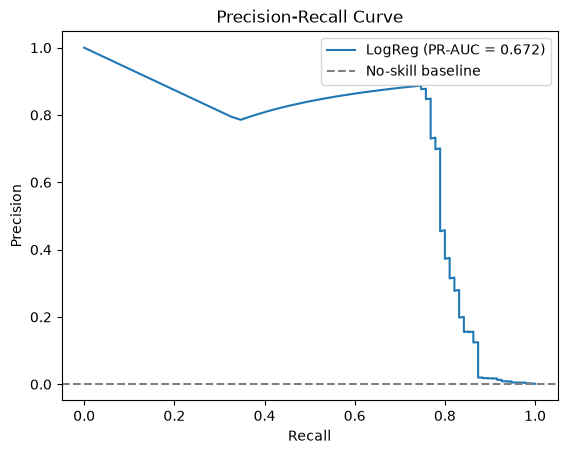

In [11]:
from sklearn.metrics import average_precision_score, precision_recall_curve

y_proba = base_pipe.predict_proba(X_test)[:, 1]   # probability of fraud
pr_auc = average_precision_score(y_test, y_proba)
print("PR-AUC:", round(pr_auc, 4))

precision, recall, thresholds = precision_recall_curve(y_test, y_proba)
plt.plot(recall, precision, label=f"LogReg (PR-AUC = {pr_auc:.3f})")
plt.axhline(y_test.mean(), linestyle="--", color="gray", label="No-skill baseline")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()

In [12]:
from sklearn.metrics import precision_score, recall_score, f1_score

results = []

def add_result(name, y_true, y_proba, threshold=0.5):
    y_pred = (y_proba >= threshold).astype(int)
    results.append({
        "model": name,
        "PR-AUC": round(average_precision_score(y_true, y_proba), 4),
        "precision": round(precision_score(y_true, y_pred), 4),
        "recall": round(recall_score(y_true, y_pred), 4),
        "f1": round(f1_score(y_true, y_pred), 4),
    })

add_result("LogReg (balanced)", y_test, y_proba)
pd.DataFrame(results)

,model,PR-AUC,precision,recall,f1
0,LogReg (balanced),0.6719,0.0562,0.8737,0.1057


## Baseline: Logistic Regression (class_weight='balanced')

- Setup: stratified 80/20 split (95 frauds in test), StandardScaler on Time and Amount inside a Pipeline, all V features kept.
- At threshold 0.5: recall 0.87 (83 of 95 frauds caught), precision 0.056, F1 0.106.
- Confusion matrix: 1,393 false alarms and 12 missed frauds. Accuracy (0.975) is misleading.
- PR-AUC = 0.672 (no-skill ≈ 0.0017).
- The PR curve keeps precision around 0.8-0.9 up to recall ~0.75 before collapsing, so the default 0.5 threshold is a poor operating point. Threshold tuning should greatly improve precision.
- Caveat: only 95 test frauds, so metrics are noisy. Threshold will be chosen using training data only.

Accuracy Score:- 0.9756987276636239
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56651
           1       0.06      0.87      0.11        95

    accuracy                           0.98     56746
   macro avg       0.53      0.92      0.55     56746
weighted avg       1.00      0.98      0.99     56746



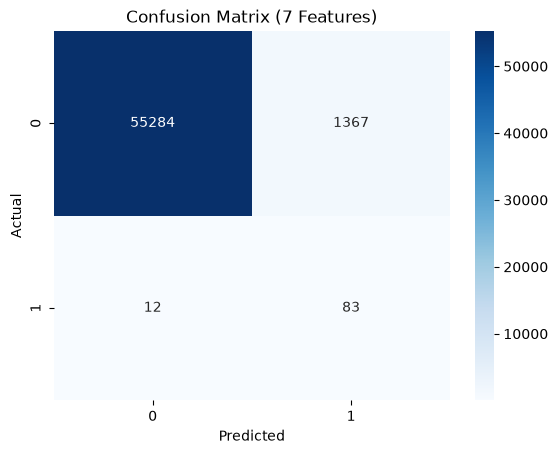

In [13]:
cols=['V4', 'V10','V11', 'V12', 'V14', 'Time', 'Amount']

from sklearn.base import clone

base_pipe_clone=clone(base_pipe)

X_train_small=X_train[cols]
X_test_small=X_test[cols]

base_pipe_clone.fit(X_train_small,y_train)
y_pred_small=base_pipe_clone.predict(X_test_small)

print(f'Accuracy Score:- {accuracy_score(y_test,y_pred_small)}')
print(classification_report(y_test,y_pred_small))

cm = confusion_matrix(y_test, y_pred_small)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (7 Features)')

plt.show()

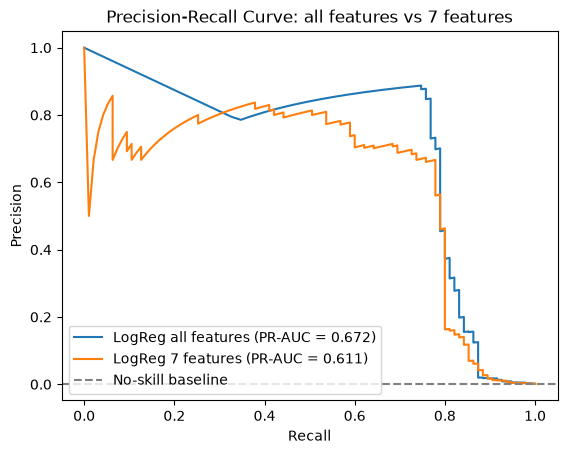

In [14]:
y_proba_small = base_pipe_clone.predict_proba(X_test_small)[:, 1]   # probability of fraud
pr_auc_small = average_precision_score(y_test, y_proba_small)

p1, r1, _ = precision_recall_curve(y_test, y_proba)
p2, r2, _ = precision_recall_curve(y_test, y_proba_small)

plt.plot(r1, p1, label=f"LogReg all features (PR-AUC = {pr_auc:.3f})")
plt.plot(r2, p2, label=f"LogReg 7 features (PR-AUC = {pr_auc_small:.3f})")
plt.axhline(y_test.mean(), linestyle="--", color="gray", label="No-skill baseline")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve: all features vs 7 features")
plt.legend()
plt.show()

add_result("LogReg (7 Features)",y_test,y_proba_small)

## Results summary

In [15]:
pd.DataFrame(results)

,model,PR-AUC,precision,recall,f1
0,LogReg (balanced),0.6719,0.0562,0.8737,0.1057
1,LogReg (7 Features),0.6113,0.0572,0.8737,0.1074


- Threshold 0.5 hides the difference between models, so PR-AUC is the main comparison.
- Both models have very low precision (~0.056) at 0.5 because class weights push probabilities too high. Threshold tuning should fix this.
- Decision: keep all 30 features as the default. Tree models (XGBoost, LightGBM) will be tested on both feature sets.

## Reduced feature set (V4, V10, V11, V12, V14, Time, Amount)

- Same pipeline and split as the baseline, with 7 features instead of 30.
- At threshold 0.5 the results are nearly identical: 83/95 frauds caught, 12 missed, 1,367 false alarms (vs 1,393).
- PR-AUC is lower: 0.611 vs 0.672. Between recall 0.5 to 0.75 the full model keeps precision around 0.8-0.88, while the reduced model stays around 0.7-0.8.
- The 23 dropped features carry useful signal, so the EDA-based shortlist is not enough on its own.
- Caveat: the 7 features were chosen from EDA on the full dataset, which favors the reduced model, and with only 95 test frauds the early jagged part of the curve is noise.

## Next steps
- Cross-validate on the training set for steadier estimates (the test set has only 95 frauds).
- Compare class weights vs SMOTE, then XGBoost and LightGBM.
- Choose the threshold using training data only, then evaluate once on the test set.